# Voorspel verhuuraantallen 2026 – CityBike

**Machine Learning ADS&AI 2026-27 · Portfolio-opdracht 2**
De Haagse Hogeschool

| Teamgegevens | |
|---|---|
| **Teamnaam op Kaggle** | `BAS` |
| **Competitie** | [Voorspel verhuuraantallen 2026](https://www.kaggle.com/competitions/voorspel-verhuuraantallen-2026) |
| **Datum** | november 2026 |

| Naam | Studentnummer | Kaggle-gebruikersnaam |
|---|---|---|
| `[Baset Paiman]` | `[24071005]` | `[basetpaimam]` |
| `[Alisha]` | `[25033646]` | `[alisharampersad]` |
| `[Shalini]` | `[nummer]` | `[gebruikersnaam]` |

## Inhoudsopgave

1. Inleiding
2. Voorbereiding: libraries en data
3. Exploratieve data-analyse (opdracht 1)
4. Time series feature engineering (opdracht 2)
5. Modelleren (opdracht 3)
6. Bevindingen (opdracht 3)
7. Conclusie en aanbevelingen (opdracht 4)
8. Bronnenlijst

## 1. Inleiding

### 1.1 Context en doel

CityBike verhuurt fietsen op verschillende locaties in een grote stad. Staan
er te weinig fietsen, dan kunnen klanten niet huren. Staan er te veel, dan
staan fietsen en stallingsplekken voor niets stil. Als CityBike vooraf weet
hoeveel fietsen er per uur nodig zijn, kan het bedrijf de fietsen slimmer
verdelen en onderhoud plannen op rustige momenten.

Onze opdracht is om voor elk uur van 1 t/m 19 december 2012 te voorspellen hoeveel
fietsen er worden verhuurd (kolom `cnt`). We hebben daarvoor uurdata van
1 januari 2011 t/m 30 november 2012 met informatie over het weer, feestdagen
en het tijdstip.

### 1.2 Aanpak en leeswijzer

We volgen de stappen van het data-scienceproces:

| Hoofdstuk | Wat doen we? |
|---|---|
| 3. EDA | Data leren kennen, fouten opsporen en opschonen, patronen zoeken. |
| 4. Feature engineering | Trend, seizoenen (Fourier), cycli en autocorrelatie onderzoeken en omzetten in features. We testen elke groep features met cross-validatie. |
| 5. Modelleren | Zes machine-learningmodellen, twee tijdreeksmodellen (SARIMAX en een vrije keuze; Prophet), een hybride model en een stacking-ensemble. Elk model krijgt cross-validatie en hyperparameter tuning. |
| 6. Bevindingen | Resultaten naast elkaar en de Kaggle-scores. |
| 7. Conclusie | Belangrijkste features, advies aan CityBike en modelkeuze. |

Feature engineering en modelleren deden we in de praktijk niet netjes na
elkaar maar in rondjes: feature toevoegen → model testen → terug naar de
features. In paragraaf 4.7 laten we die iteraties zien.

### 1.3 Evaluatiemaat: RMSE

Kaggle beoordeelt de voorspellingen met de **Root Mean Squared Error**:

$$
\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2}
$$

Hierin is $y_i$ het echte aantal verhuurde fietsen in uur $i$ en
$\hat{y}_i$ onze voorspelling. De RMSE is in dezelfde eenheid als de target
(fietsen per uur). Omdat de fouten gekwadrateerd worden, tellen grote fouten
extra zwaar mee. Voor CityBike is dat logisch: een flinke misser in de
ochtendspits (lege stations) is erger dan een paar fietsen verschil midden in
de nacht. **De eis voor deze opdracht is een RMSE onder de 80 op Kaggle.**


## 2. Voorbereiding: libraries en data

### 2.1 Libraries

In [3]:
# Basis libraries
!pip install prophet
import logging
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fourier-analyse en tijdreeks-features
from scipy.fft import fft, ifft
from statsmodels.tsa.deterministic import CalendarFourier
from statsmodels.tsa.deterministic import DeterministicProcess
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Tijdreeksmodellen
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

# Regressiemodellen
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, PoissonRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

# Metrics en cross-validatie
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.model_selection import train_test_split

   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   -------------------------------- ------- 9.7/12.1 MB 57.6 MB/s eta 0:00:01
   ---------------------------------------- 12.1/12.1 MB 39.8 MB/s eta 0:00:00
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 37.6 MB/s eta 0:00:00

   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------------- 1/4 [holidays]
   ---------- ----------------------

### 2.2 Instellingen

Een paar vaste waarden gebruiken we in het hele notebook. De belangrijkste is
de **horizon**: Kaggle vraagt voorspellingen voor 19 dagen × 24 uur = 456 uur.
Die lengte gebruiken we ook voor onze testset en voor elk validatieblok in de
cross validatie zodat we steeds dezelfde taak oefenen als op Kaggle.

In [4]:
# Waarschuwingen die niets over de uitkomst zeggen verbergen
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', module='statsmodels')
warnings.filterwarnings('ignore', message='IProgress not found')
os.environ['PYTHONWARNINGS'] = 'ignore'  # ook in parallelle processen
logging.getLogger('cmdstanpy').disabled = True
logging.getLogger('prophet').setLevel(logging.ERROR)

# Opmaak van de figuren
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 4)

# Vaste waarden
HORIZON = 19 * 24   # Kaggle-periode: 19 dagen van 24 uur = 456 uur
N_SPLITS = 5        # aantal validatieblokken in TimeSeriesSplit
RANDOM_STATE = 42   # zelfde uitkomst bij elke run

### 2.3 Data inladen

We lezen de datumkolom meteen in als datetime (`parse_dates`). Dan kunnen we er later makkelijk het uur, de dag en de maand uit halen.

In [5]:
# Dataframes maken
df = pd.read_csv('train.csv', parse_dates=['date_hour'])
df_test = pd.read_csv('test.csv', parse_dates=['date_hour'])
sample = pd.read_csv('sample_submission.csv', parse_dates=['date_hour'])

print('train :', df.shape, df['date_hour'].min(), 't/m',
      df['date_hour'].max())
print('test  :', df_test.shape, df_test['date_hour'].min(), 't/m',
      df_test['date_hour'].max())
df.head()

train : (16637, 8) 2011-01-01 00:00:00 t/m 2012-11-30 23:00:00
test  : (456, 7) 2012-12-01 00:00:00 t/m 2012-12-19 23:00:00


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1


## 3. Exploratieve data-analyse (opdracht 1)

In dit hoofdstuk leren we de data kennen. We kijken eerst naar de datatypes en
de basisstatistieken, zoeken daarna naar fouten en gaten, schonen de data op en
zoeken tot slot met visualisaties naar patronen in de tijd en in het weer.

### 3.1 Datatypes en basisstatistieken

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16637 entries, 0 to 16636
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date_hour   16637 non-null  datetime64[ns]
 1   holiday     16637 non-null  int64         
 2   weathersit  16637 non-null  int64         
 3   temp        16637 non-null  float64       
 4   atemp       16637 non-null  float64       
 5   hum         16637 non-null  float64       
 6   windspeed   16637 non-null  float64       
 7   cnt         16637 non-null  int64         
dtypes: datetime64[ns](1), float64(4), int64(3)
memory usage: 1.0 MB


In [7]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date_hour,16637,2011-12-18 02:20:08.294764544,2011-01-01 00:00:00,2011-06-27 05:00:00,2011-12-18 06:00:00,2012-06-09 02:00:00,2012-11-30 23:00:00,NaN
holiday,16637.0,0.028671,0.0,0.0,0.0,0.0,1.0,0.166885
weathersit,16637.0,1.41558,1.0,1.0,1.0,2.0,4.0,0.637298
temp,16637.0,0.504745,0.02,0.34,0.52,0.66,1.0,0.192369
atemp,16637.0,0.482608,0.0,0.3333,0.5,0.6212,1.0,0.171557
hum,16637.0,0.624756,0.0,0.47,0.62,0.78,1.0,0.193227
windspeed,16637.0,0.19031,0.0,0.1045,0.194,0.2537,0.8507,0.121915
cnt,16637.0,190.477009,1.0,41.0,143.0,282.0,977.0,182.026755


In [8]:
# Hoe vaak komt elke waarde voor bij de categorische kolommen?
for col in ['holiday', 'weathersit']:
    print(df[col].value_counts().sort_index().to_dict())

{0: 16160, 1: 477}
{1: 11078, 2: 4207, 3: 1349, 4: 3}


**Wat zien we?**

- Er zijn **16.637 regels** en geen lege cellen. `date_hour` is netjes als
  datetime ingelezen, de rest is numeriek.
- `cnt` (de target) is een **telling**: altijd een geheel getal ≥ 1. Het
  gemiddelde (190,5) ligt flink boven de mediaan
  (143). De verdeling is dus scheef naar rechts: veel rustige
  uren en een paar hele drukke uren (maximaal 977 fietsen in één uur).
- `holiday` is 0/1. `weathersit` is een categorie (1 = helder weer … 4 = zwaar
  weer), maar wel met een volgorde. Type 4 komt maar **3 keer** voor.
- `temp`, `atemp`, `hum` en `windspeed` zijn al **genormaliseerd** tussen 0
  en 1. Volgens de beschrijving van de oorspronkelijke dataset (Fanaee-T,
  2013) is de temperatuur omgerekend met $(t - t_{min}) / (t_{max} -
  t_{min})$, met $t_{min} = -8$ °C en $t_{max} = 39$ °C
  (gevoelstemperatuur: −16 en 50 °C). De luchtvochtigheid is gedeeld door 100
  en de windsnelheid door 67. Terugrekenen gaat dus met
  $t = 47 \cdot \text{temp} - 8$: een `temp` van 0,5 is ongeveer 15,5 °C.
- Er zijn geen kolommen voor seizoen, weekdag of werkdag. Die tijdselementen
  maken we zelf straks in d notebook
- De data komt oorspronkelijk van het fietsdeelsysteem Capital Bikeshare in
  Washington D.C. (Fanaee-T, 2013). Daardoor kunnen we uitschieters koppelen aan
  echte gebeurtenissen in die stad.


### 3.2 Ontbrekende uren

Van 1 januari 2011 00:00 t/m 30 november 2012 23:00 zijn er 700 × 24 = 16.800
uren. We hebben er maar 16.637, dus er missen uren. Volgens de les moeten de
tijdstappen gelijk verdeeld zijn.

In [9]:
# Tijd als index en de tijdas aanvullen tot elk uur
dfh = df.set_index('date_hour').asfreq('h')
missing = dfh['cnt'].isna()
print('aantal uren in de periode:', len(dfh))
print('ontbrekende uren         :', missing.sum())
# Hoeveel fietsen werden er verhuurd in het uur vóór en ná een gat?
neighbours = pd.concat([dfh['cnt'].shift(1)[missing],
                        dfh['cnt'].shift(-1)[missing]])
print('mediaan verhuur in de buururen:', neighbours.median())

aantal uren in de periode: 16800
ontbrekende uren         : 163
mediaan verhuur in de buururen: 3.0


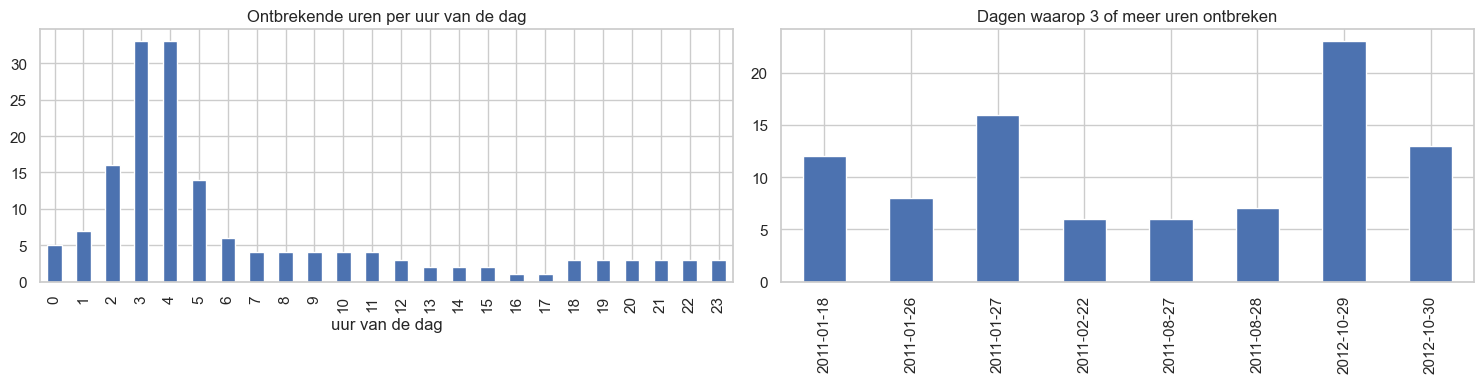

In [10]:
# Op welk uur van de dag en op welke dagen ontbreken de regels?
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
missing.groupby(dfh.index.hour).sum().plot(
    kind='bar', ax=ax[0], title='Ontbrekende uren per uur van de dag')
ax[0].set_xlabel('uur van de dag')
missing_days = missing.groupby(dfh.index.date).sum()
missing_days[missing_days >= 3].plot(
    kind='bar', ax=ax[1], title='Dagen waarop 3 of meer uren ontbreken')
plt.tight_layout()
plt.show()

In [11]:
# Hoe zag het weer eruit op de dagen met veel ontbrekende uren?
days = missing_days[missing_days >= 6].index.astype(str)
storm_days = pd.DataFrame({
    'ontbrekende uren': missing_days[missing_days >= 6].values,
    'verhuur die dag': [df.loc[df['date_hour'].dt.date.astype(str) == d,
                               'cnt'].sum() for d in days],
    'slechtste weertype': [df.loc[df['date_hour'].dt.date.astype(str) == d,
                                  'weathersit'].max() for d in days]},
    index=days)
storm_days

,ontbrekende uren,verhuur die dag,slechtste weertype
2011-01-18,12,683,2
2011-01-26,8,506,4
2011-01-27,16,431,1
2011-02-22,6,1450,2
2011-08-27,6,1115,3
2011-08-28,7,4334,3
2012-10-29,23,22,3
2012-10-30,13,1096,3


**Interpretatie.** de ontbrekende uren zitten vooral **'s nachts tussen 2 en
5 uur**. De data is per uur opgeteld uit losse ritten: als er in een uur geen
enkele rit begint, is er ook geen regel. De uren vlak voor en na een gat hebben
maar een handvol verhuringen (mediaan 3). Een ontbrekend uur betekent dus
vrijwel zeker **0 verhuringen**.

Een paar dagen missen veel uren tegelijk. Soms was het weer toen extreem zoals
op 26 januari 2011 (weertype 4: zware regen of sneeuw). De grootste uitschieter
is **29–30 oktober 2012**. Op 29 oktober zijn in totaal maar 22 fietsen verhuurd: dat
is geen gewone dag, maar een uitzondering. In het artikel waarin deze dataset
is gepubliceerd worden zulke uitzonderlijke dagen juist als *events*
opgespoord (Fanaee-T & Gama, 2014).

### 3.3 Onjuiste en uitzonderlijke waarden

In [12]:
# Een paar opvallende waarden tellen
print('weathersit = 4:', (df['weathersit'] == 4).sum(), 'uur')
print('hum = 0       :', (df['hum'] == 0).sum(), 'uur, op',
      df.loc[df['hum'] == 0, 'date_hour'].dt.date.unique())
print('windspeed = 0 :', (df['windspeed'] == 0).sum(), 'uur',
      f"({(df['windspeed'] == 0).mean():.0%})")

weathersit = 4: 3 uur
hum = 0       : 22 uur, op [datetime.date(2011, 3, 10)]
windspeed = 0 : 2072 uur (12%)


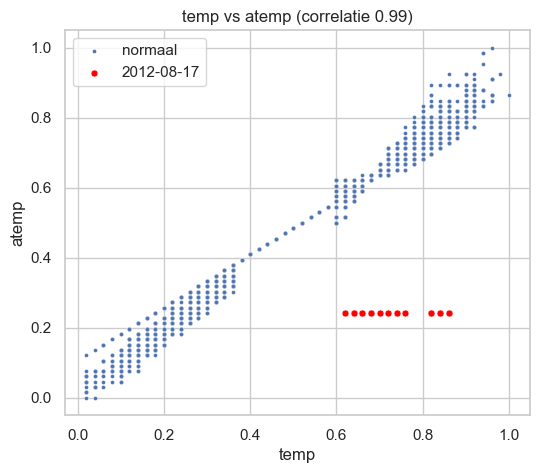

In [13]:
# temp en atemp lijken bijna hetzelfde: klopt dat overal?
odd = (df['atemp'] - df['temp']).abs() > 0.3
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(data=df[~odd], x='temp', y='atemp', s=8, ax=ax,
                label='normaal')
sns.scatterplot(data=df[odd], x='temp', y='atemp', s=25, color='red',
                ax=ax, label=str(df.loc[odd, 'date_hour'].dt.date.iloc[0]))
ax.set_title(f"temp vs atemp (correlatie {df['temp'].corr(df['atemp']):.2f})")
plt.show()

**Wat doen we hiermee?**

| Probleem | Waarom is het een probleem? | Oplossing |
|---|---|---|
| 163 ontbrekende uren | Tijdreeksmethoden (FFT, ACF, SARIMAX, trend) verwachten elk uur een waarde | Uur toevoegen met `cnt = 0`; het weer nemen we over van het uur ervoor |
| `hum = 0` op 10 maart 2011 | Een luchtvochtigheid van 0% bestaat niet in Washington; dit is een sensorfout | Op `NaN` zetten en lineair interpoleren |
| `weathersit = 4` (3 uur) | Te weinig voorbeelden om iets van te leren | Samenvoegen met type 3 (slecht weer) |
| `atemp` op 17 augustus 2012 | Een hele dag dezelfde vreemde gevoelstemperatuur; verder is `atemp` vrijwel gelijk aan `temp` (correlatie 0,99) | `atemp` gebruiken we niet als feature: het voegt niets toe en is één keer fout |
| `windspeed = 0` (12%) | Kan echt windstil zijn, maar kan ook een ontbrekende meting zijn | Laten staan: we kunnen het niet controleren en de wind heeft weinig invloed |
| Orkaan Sandy (29–30 okt 2012) | Het systeem lag stil; dat kan geen enkel model uit het weer halen | In de tijdreeks laten staan, maar **niet gebruiken om ML-modellen te trainen**|

### 3.4 Data opschonen

We stoppen alle stappen in een functie en zo kunnen we precies dezelfde
bewerkingen ook op de Kaggle testdata uitvoeren.

In [14]:
def clean_data(data):
    """
    Schoon de uurdata op (zie de tabel in paragraaf 3.3).

    Parameters
    ----------
    data : DataFrame
        Data met de tijd (per uur) als index.

    Returns
    -------
    DataFrame
        Opgeschoonde data met een volledige uur-index.
    """
    weather_cols = ['weathersit', 'temp', 'atemp', 'hum', 'windspeed']
    data = data.asfreq('h')
    if 'cnt' in data.columns:
        # Ontbrekend uur = er is in dat uur geen fiets verhuurd
        data['cnt'] = data['cnt'].fillna(0)
    # Weer van het vorige uur overnemen
    data[weather_cols] = data[weather_cols].ffill()
    # Feestdag geldt voor de hele dag
    day = data.index.normalize()
    data['holiday'] = data['holiday'].groupby(day).transform('max')
    # Sensorfout: luchtvochtigheid van 0 bestaat niet
    data['hum'] = data['hum'].replace(0, np.nan).interpolate()
    # Weertype 4 komt bijna niet voor: samenvoegen met type 3
    data['weathersit'] = data['weathersit'].replace(4, 3)
    int_cols = ['holiday', 'weathersit']
    data[int_cols] = data[int_cols].astype(int)
    return data


dfh = clean_data(df.set_index('date_hour'))
dft = clean_data(df_test.set_index('date_hour'))
print('train:', dfh.shape, '| test:', dft.shape)
print('lege cellen na opschonen:', dfh.isna().sum().sum(), '+',
      dft.isna().sum().sum())

train: (16800, 7) | test: (456, 6)
lege cellen na opschonen: 0 + 0


### 3.5 Tijdreekselementen toevoegen

Uit de tijd halen we, net als in hoe we de les hebben geleerd, het uur, de dag
van de week, het weeknummer, de maand en het jaar en de tijd staat bij ons in de
index daarom gebruiken we `index.hour` in plaats van `.dt.hour`.

Daarnaast maken we twee eigen tijdselementen:

- `workingday`: 1 op maandag t/m vrijdag als het géén feestdag is. In de
  dataset ontbreekt deze kolom, maar we verwachten dat werkdagen er heel anders
  uitzien dan weekenden (woon-werkverkeer).
- `Hour_daytype`: de combinatie van uur en soort dag, bijvoorbeeld `8_werk` of
  `8_vrij`. Straks in de notebook tonen we waarom we die nodig hebben.

In [15]:
def add_time_features(data):
    """
    Voeg tijdselementen toe aan een DataFrame met een uur-index.

    Parameters
    ----------
    data : DataFrame
        Data met de tijd als index.

    Returns
    -------
    DataFrame
        Kopie van de data met extra tijdkolommen.
    """
    data = data.copy()
    data['Hour'] = data.index.hour
    data['Day'] = data.index.dayofweek          # 0 = maandag, 6 = zondag
    data['DayName'] = data.index.day_name()
    data['Week'] = data.index.isocalendar().week.astype(int)
    data['Month'] = data.index.month
    data['Year'] = data.index.year
    # Werkdag: maandag t/m vrijdag en geen feestdag
    data['workingday'] = ((data['Day'] < 5)
                          & (data['holiday'] == 0)).astype(int)
    # Combinatie van uur en soort dag, bv. '8_werk' of '8_vrij'
    day_type = np.where(data['workingday'] == 1, 'werk', 'vrij')
    data['Hour_daytype'] = data['Hour'].astype(str) + '_' + day_type
    return data


dfh = add_time_features(dfh)
dft = add_time_features(dft)
dfh.head()

,holiday,weathersit,temp,atemp,hum,windspeed,cnt,Hour,Day,DayName,Week,Month,Year,workingday,Hour_daytype
date_hour,,,,,,,,,,,,,,,
2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16.0,0,5,Saturday,52,1,2011,0,0_vrij
2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40.0,1,5,Saturday,52,1,2011,0,1_vrij
2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32.0,2,5,Saturday,52,1,2011,0,2_vrij
2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13.0,3,5,Saturday,52,1,2011,0,3_vrij
2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1.0,4,5,Saturday,52,1,2011,0,4_vrij


### 3.6 Het verloop door de tijd

Voor onze geval is een lijngrafiek de beste manier om een tijdreeks te bekijken. Een lijn met 16.800 uren is erg druk en daarom tekenen we de reeks ook per dag en
per week (met `resample`).

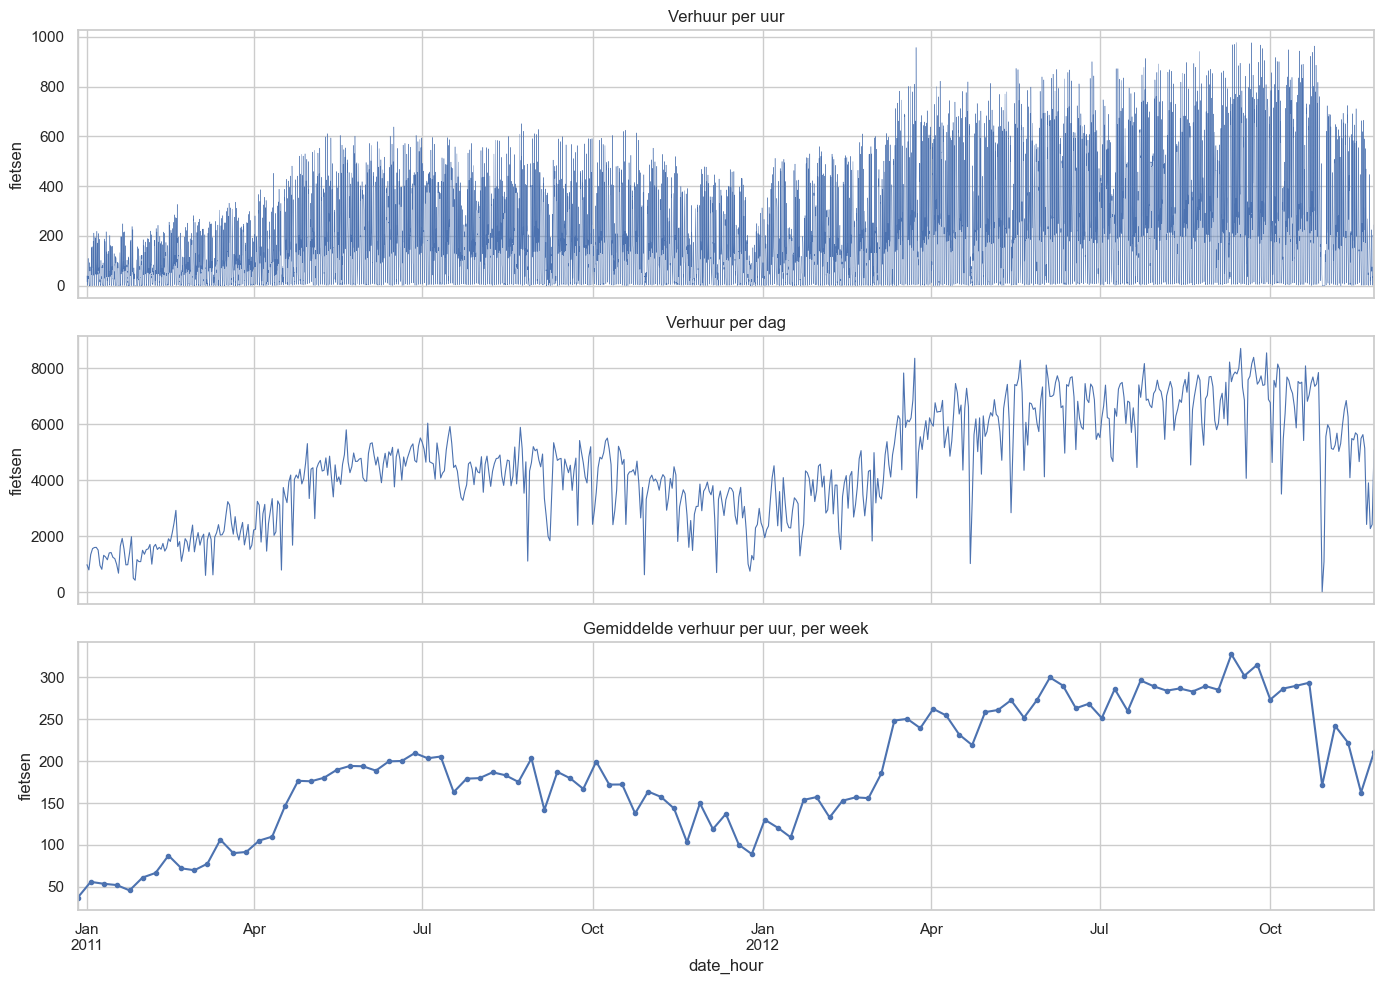

In [16]:
fig, ax = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
dfh['cnt'].plot(ax=ax[0], lw=0.3, title='Verhuur per uur')
dfh['cnt'].resample('D').sum().plot(ax=ax[1], lw=0.8,
                                    title='Verhuur per dag')
dfh['cnt'].resample('W').mean().plot(
    ax=ax[2], marker='.', title='Gemiddelde verhuur per uur, per week')
for a in ax:
    a.set_ylabel('fietsen')
plt.tight_layout()
plt.show()

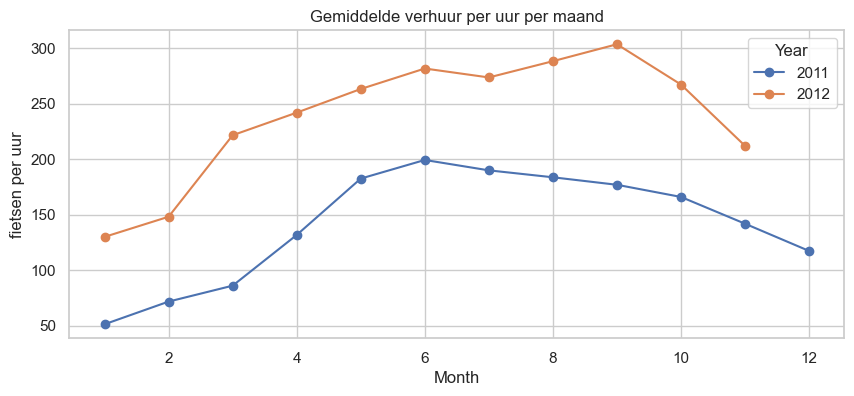

Groei januari-november 2012 t.o.v. 2011: 66%


Month,1,2,3,4,5,6,7,8,9,10,11,12
Year,,,,,,,,,,,,
2011,51.33,71.75,86.08,131.76,182.56,199.32,189.97,183.72,176.97,166.01,141.90,117.37
2012,130.03,148.19,221.61,241.98,263.26,281.71,273.67,288.31,303.57,267.26,212.03,NaN
groei 2012 t.o.v. 2011,1.53,1.07,1.57,0.84,0.44,0.41,0.44,0.57,0.72,0.61,0.49,NaN


In [17]:
# Elke maand van 2011 naast dezelfde maand in 2012
monthly = dfh.groupby(['Month', 'Year'])['cnt'].mean().unstack()
monthly['groei 2012 t.o.v. 2011'] = monthly[2012] / monthly[2011] - 1
ax = monthly[[2011, 2012]].plot(marker='o', figsize=(10, 4),
                                title='Gemiddelde verhuur per uur per maand')
ax.set_ylabel('fietsen per uur')
plt.show()
# Eerlijke vergelijking: van 2012 hebben we geen december
jan_nov = dfh[dfh['Month'] <= 11].groupby('Year')['cnt'].mean()
print(f'Groei januari-november 2012 t.o.v. 2011: '
      f'{jan_nov[2012] / jan_nov[2011] - 1:.0%}')
monthly.round(2).T

**Wat zien we?**

1. **Trend:** 2012 ligt elke maand flink hoger dan 2011. Over januari t/m
   november verhuurt CityBike in 2012 66% meer fietsen per uur
   dan in 2011. De groei is niet constant: in januari–maart is 2012 meer dan
   twee keer zo druk, in de zomer 'maar' ruim 40% en in de herfst 50–70%. Een
   rechte lijn door de hele periode is dus een vereenvoudiging.
2. **Jaarseizoen:** in de zomer worden veel meer fietsen gehuurd dan in de
   winter. December en januari zijn de rustigste maanden. Voor ons is dat
   belangrijk: we moeten juist een **rustige maand** voorspellen.
3. **Dag- en weekpatroon:** in de uurgrafiek zie je dat de reeks elke dag op
   en neer gaat. Dat bekijken we hieronder hierna in onze notebook.
4. **Uitschieters:** de dip eind oktober 2012 is orkaan Sandy.

### 3.7 Patronen binnen de dag en de week

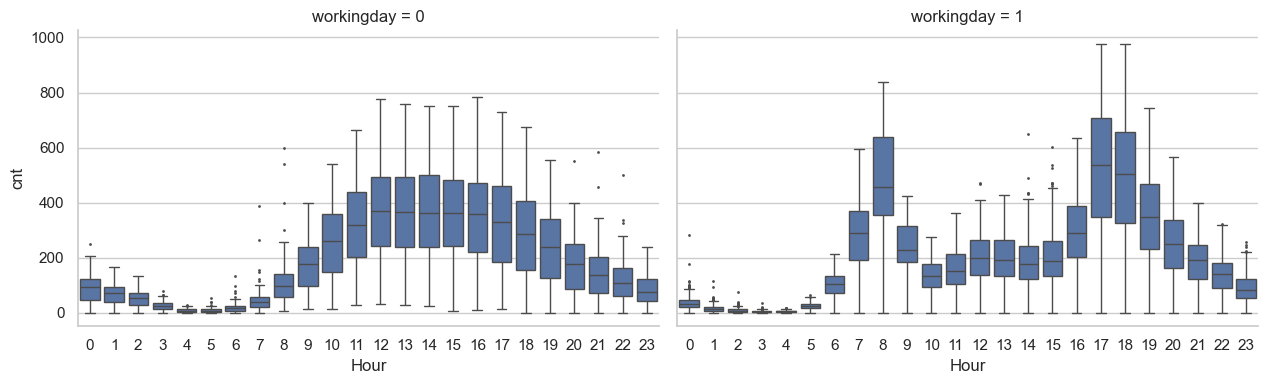

In [18]:
# Verdeling per uur, voor werkdagen en vrije dagen apart
sns.catplot(data=dfh, x='Hour', y='cnt', col='workingday', kind='box',
            height=4, aspect=1.6, fliersize=1)
plt.show()

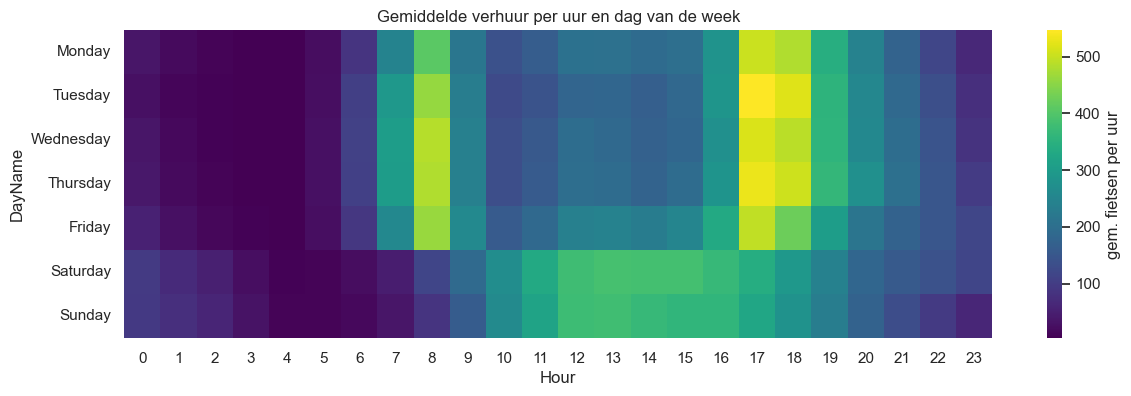

In [19]:
# Gemiddelde verhuur per uur en per dag van de week (heatmap)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday',
             'Saturday', 'Sunday']
heat = dfh.pivot_table(index='DayName', columns='Hour', values='cnt',
                       aggfunc='mean').loc[day_order]
plt.figure(figsize=(14, 4))
sns.heatmap(heat, cmap='viridis', cbar_kws={'label': 'gem. fietsen per uur'})
plt.title('Gemiddelde verhuur per uur en dag van de week')
plt.show()

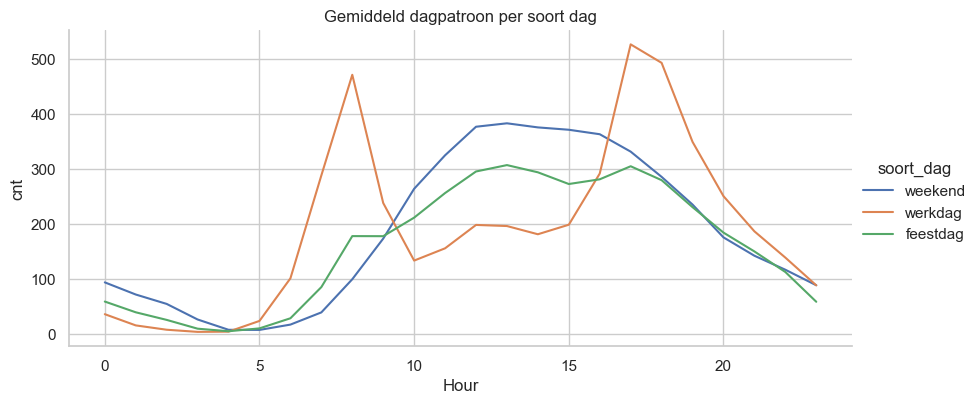

In [20]:
# Is een feestdag meer een werkdag of meer een weekenddag?
dfh['soort_dag'] = np.select([dfh['holiday'] == 1, dfh['Day'] >= 5],
                             ['feestdag', 'weekend'], 'werkdag')
sns.relplot(data=dfh, x='Hour', y='cnt', hue='soort_dag', kind='line',
            errorbar=None, height=4, aspect=2.2)
plt.title('Gemiddeld dagpatroon per soort dag')
plt.show()
dfh = dfh.drop(columns='soort_dag')

**Wat zien we?**

- Op **werkdagen** zijn er twee spitsen: rond **8 uur** en rond **17–18 uur**.
  Dat is woon werkverkeer en tussendoor is het rustiger.
- In het **weekend** is er geen spits, maar een brede bult tussen 10 en 18 uur:
  recreatief fietsen.
- Een **feestdag** lijkt veel meer op een weekenddag dan op een werkdag. Dat
  bevestigt onze definitie van `workingday` (weekend of feestdag = vrije dag).
- Het belangrijkste inzicht: **het uurpatroon hangt af van het soort dag**.
  Een model dat het effect van "uur" en het effect van "dag" alleen optelt,
  kan dat niet goed leren dan krijgt zaterdag ook een kleinere ochtendspits.
  Daarom maken we straks de interactie `Hour_daytype` (uur × soort dag).
- De boxplots hebben veel uitschieters naar boven vooral in de spits. Dat zijn
  geen fouten, maar drukke zomerdagen. De spreiding is groter naarmate het
  gemiddelde hoger is en dat noemen we later *heteroscedasticiteit*.

### 3.8 Relatie tussen het weer en de verhuur

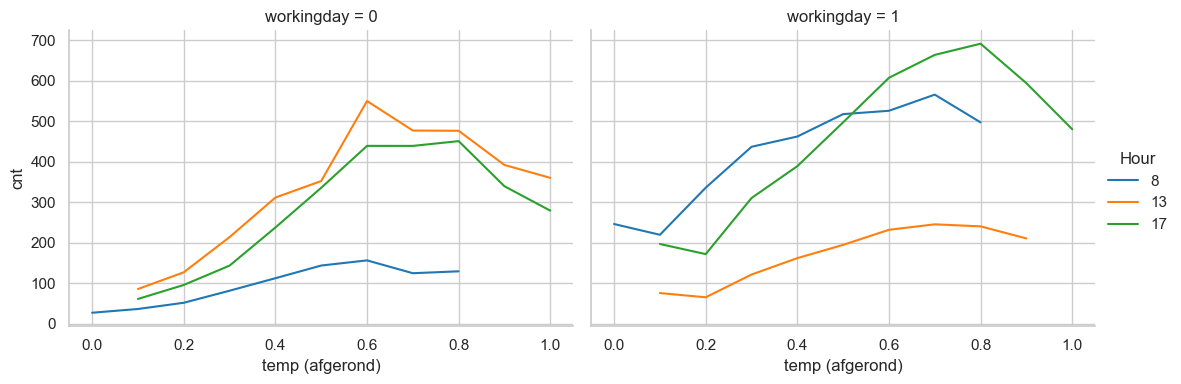

In [21]:
# Effect van temperatuur op drie uren: 8 uur (spits), 13 uur en 17 uur
sel = dfh[dfh['Hour'].isin([8, 13, 17])].copy()
sel['temp (afgerond)'] = sel['temp'].round(1)
sns.relplot(data=sel, x='temp (afgerond)', y='cnt', hue='Hour',
            col='workingday', kind='line', errorbar=None, palette='tab10',
            height=4, aspect=1.4)
plt.show()

In [22]:
# Hoeveel keer zoveel verhuur bij warm (temp > 0,6) als bij koud (<= 0,3)?
# Per jaar apart, zodat de groei van 2011 naar 2012 niet meetelt.
temp_group = pd.cut(dfh['temp'], [0, 0.3, 0.6, 1.0],
                    labels=['koud', 'mild', 'warm'])
means = dfh.groupby(['Year', 'workingday', 'Hour', temp_group],
                    observed=True)['cnt'].mean().unstack()
ratio = (means['warm'] / means['koud']).unstack('Year')
ratio = ratio.loc[[(1, 8), (1, 13), (1, 17), (0, 13)]]
ratio.index = ['werkdag 8 uur', 'werkdag 13 uur', 'werkdag 17 uur',
               'vrije dag 13 uur']
ratio.round(2)

Year,2011,2012
werkdag 8 uur,1.80,1.36
werkdag 13 uur,2.63,2.42
werkdag 17 uur,2.81,2.69
vrije dag 13 uur,3.16,2.58


Gemiddeld verschil met helder weer (zelfde uur): {1: '+0%', 2: '-10%', 3: '-50%'}


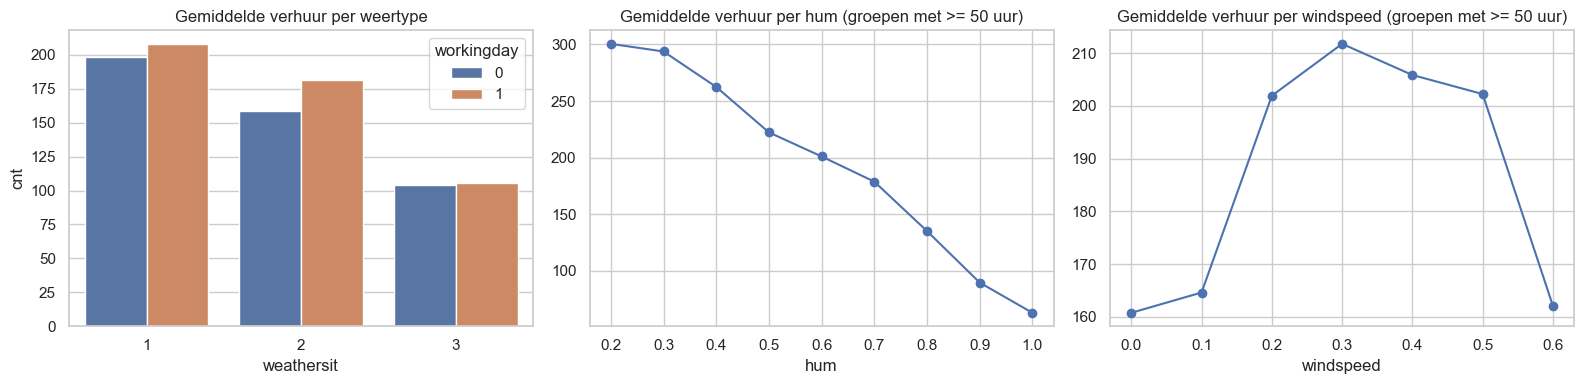

In [23]:
# Effect van het weertype: vergelijk binnen hetzelfde uur van de dag
per_hour = dfh.groupby(['Hour', 'weathersit'])['cnt'].mean().unstack()
effect = (per_hour.div(per_hour[1], axis=0) - 1).mean()
print('Gemiddeld verschil met helder weer (zelfde uur):',
      {ws: f'{value:+.0%}' for ws, value in effect.items()})

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=dfh, x='weathersit', y='cnt', hue='workingday', ax=ax[0],
            errorbar=None)
ax[0].set_title('Gemiddelde verhuur per weertype')
for a, col in zip(ax[1:], ['hum', 'windspeed']):
    grouped = dfh.groupby(dfh[col].round(1))['cnt']
    # Alleen groepen met genoeg uren, anders is het gemiddelde toeval
    grouped.mean()[grouped.size() >= 50].plot(ax=a, marker='o')
    a.set_title(f'Gemiddelde verhuur per {col} (groepen met >= 50 uur)')
plt.tight_layout()
plt.show()

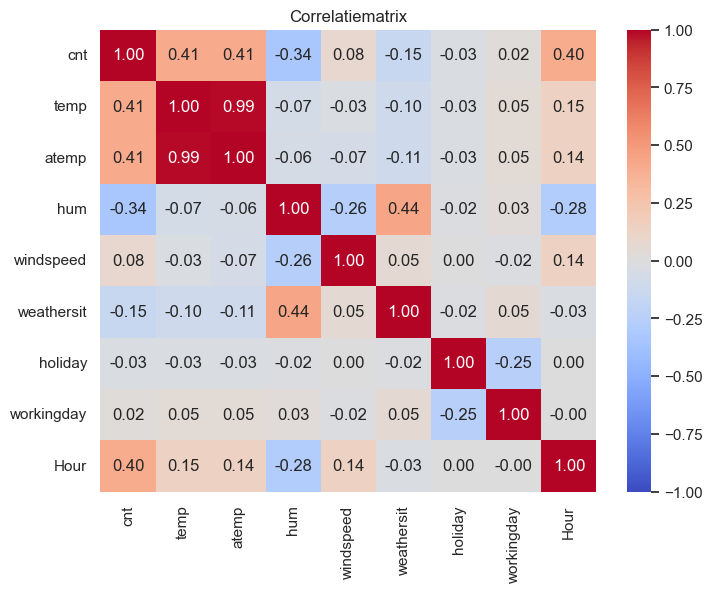

In [24]:
# Correlaties tussen de numerieke kolommen
corr_cols = ['cnt', 'temp', 'atemp', 'hum', 'windspeed', 'weathersit',
             'holiday', 'workingday', 'Hour']
plt.figure(figsize=(8, 6))
sns.heatmap(dfh[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1)
plt.title('Correlatiematrix')
plt.show()

**Wat zien we?**

- **Temperatuur** is de belangrijkste weervariabele (correlatie
  0,41 met `cnt`). Het verband is **niet lineair**: tot ongeveer
  `temp` = 0,7 (± 25 °C) stijgt de verhuur, daarna vlakt hij af of daalt hij
  weer. Dat is een reden om naast `temp` ook `temp²` als feature te proberen.
- Origineel inzicht: **de ochtendspits reageert het minst op het weer.** Om
  8 uur op een werkdag wordt bij warm weer 1,4 a 1,8 keer zoveel gefietst
  als bij koud weer. Om 13 en 17 uur op een werkdag is dat 2,4 a 2,8
  keer en om 13 uur op een vrije dag 2,6 a 3,2 keer (per jaar apart
  berekend, zodat de groei niet meetelt). Wie naar zijn werk moet, fietst
  toch wel; wie in zijn vrije tijd fietst, kijkt naar het weer. Dit is een
  interactie (weer × soort uur) die vooral boommodellen goed kunnen leren.
- **Weertype:** binnen hetzelfde uur geeft mistig weer (2) gemiddeld
  10% minder en slecht weer (3) gemiddeld 50% minder verhuur
  vergeleken met helder weer.
- **Luchtvochtigheid** hangt sterk negatief samen met de verhuur (vochtig =
  vaak regen). Let op: de luchtvochtigheid is 's nachts ook hoger (correlatie
  met `Hour` −0,28), dus een deel van dit effect is eigenlijk het tijdstip.
  **Windsnelheid** heeft weinig invloed: het gemiddelde schommelt tussen
  ongeveer 160 en 210 fietsen zonder duidelijke richting (correlatie 0,08).
- `temp` en `atemp` zijn bijna perfect gecorreleerd (0,99). In een lineair
  model geeft dat *multicollineariteit*: de coefficienten worden instabiel.
  Ook daarom laten we `atemp` weg.
- De correlatie met `Hour` (0,40) onderschat hoe belangrijk het uur is. Het
  verband is niet lineair (laag in de nacht, twee spitsen overdag) en een
  correlatie meet alleen rechte-lijn-verbanden.

### 3.9 Lijkt de testperiode op de trainingsdata?

We moeten 1–19 december 2012 voorspellen. We vergelijken het weer in die
periode met dezelfde periode een jaar eerder en met november 2012.

In [25]:
weather = ['temp', 'hum', 'windspeed']
compare = pd.DataFrame({
    '1-19 dec 2011': dfh.loc['2011-12-01':'2011-12-19', weather].mean(),
    'nov 2012': dfh.loc['2012-11', weather].mean(),
    '1-19 dec 2012 (Kaggle)': dft[weather].mean()})
for ws in [1, 2, 3]:
    compare.loc[f'aandeel weertype {ws}'] = [
        (dfh.loc['2011-12-01':'2011-12-19', 'weathersit'] == ws).mean(),
        (dfh.loc['2012-11', 'weathersit'] == ws).mean(),
        (dft['weathersit'] == ws).mean()]
compare.loc['temp in °C'] = compare.loc['temp'] * 47 - 8
compare.loc['verhuur per uur'] = [
    dfh.loc['2011-12-01':'2011-12-19', 'cnt'].mean(),
    dfh.loc['2012-11', 'cnt'].mean(), np.nan]
compare.loc['feestdagen (uren)'] = [
    dfh.loc['2011-12-01':'2011-12-19', 'holiday'].sum(),
    dfh.loc['2012-11', 'holiday'].sum(), dft['holiday'].sum()]
compare.round(3)

,1-19 dec 2011,nov 2012,1-19 dec 2012 (Kaggle)
temp,0.315,0.336,0.360
hum,0.653,0.575,0.715
windspeed,0.161,0.186,0.158
aandeel weertype 1,0.689,0.678,0.471
aandeel weertype 2,0.230,0.285,0.465
aandeel weertype 3,0.081,0.038,0.064
temp in °C,6.784,7.789,8.926
verhuur per uur,134.173,212.033,NaN
feestdagen (uren),0.000,48.000,0.000


**Wat zien we?** De testperiode is iets **zachter** dan december
2011 en november 2012 (gemiddeld 8,9 °C tegen 6,8 en 7,8 °C), maar ook
**vochtiger** (`hum` 0,72 tegen 0,65 en 0,58) en veel vaker **mistig of
bewolkt** (weertype 2 in 47% van de uren tegen 23–29%). Slecht weer
(type 3) komt ongeveer even vaak voor als normaal (6%). In de testperiode
zitten **geen feestdagen**; in november 2012 waren dat er twee (Veterans Day en
Thanksgiving, samen 48 uur). In december 2011 werden gemiddeld 134 fietsen per
uur verhuurd, in november 2012 gemiddeld 212. Door de groei verwachten we voor
december 2012 een niveau daartussen. Alle weerwaarden in de testperiode liggen
binnen het bereik van de trainingsdata: voor het weer hoeven de modellen dus
niet te extrapoleren alleen voor de tijd (de trend).

### 3.10 Belangrijkste bevindingen van de EDA

1. **Data-kwaliteit:** 163 uren ontbraken (vrijwel altijd uren zonder
   verhuur), één dag had een kapotte vochtsensor en `atemp` is een dag fout.
   Orkaan Sandy (29–30 oktober 2012) is een uitzonderlijke gebeurtenis. Alles
   is opgeschoond of apart gezet.
2. **Trend:** de verhuur groeit sterk (66% van 2011 naar 2012),
   maar de groei vlakt af. Het model moet de trend dus kunnen *extrapoleren*
   naar december 2012.
3. **Seizoenen op drie tijdschalen:** een **jaarpatroon** (zomer druk, winter
   rustig), een **weekpatroon** (werkdag vs. weekend) en een **dagpatroon**
   (twee spitsen op werkdagen, een bult in het weekend).
4. **Interacties:** het dagpatroon hangt af van het soort dag, en het weer
   heeft meer invloed op recreatieve uren dan op de spits.
5. **Weer:** temperatuur is de belangrijkste weervariabele (niet-lineair),
   daarna het weertype en de luchtvochtigheid. Wind doet weinig.
6. **Variatie groeit met het niveau:** drukke periodes schommelen meer. Dat
   wijst op een *multiplicatief* patroon; een log-transformatie van `cnt` kan
   helpen en dit onderzoeken we later in onze notebook verder.
7. **Testperiode:** december is een rustige maand zonder feestdagen in de
   testperiode met relatief mild weer.

## 4. Time series feature engineering (opdracht 2).

In dit hoofdstuk onderzoeken we de vier onderdelen uit de opdracht: **trend**,
**seizoenspatronen** (met decompositie en Fourier-analyse), **cycli en
autocorrelatie** en **overige tijdsgebaseerde features**. Of een feature echt
helpt, kun je alleen zien door te modelleren. Daarom beginnen we met de manier
waarop we testen (4.1) en met onze klasse `RegressionModels` (4.2).

### 4.1 De validatie-opzet

> Bij gewone K-fold
> cross-validatie worden de data willekeurig in stukken verdeeld. Bij een
> tijdreeks mag dat niet: je mag **nooit data uit de toekomst gebruiken om het
> verleden te voorspellen**. `TimeSeriesSplit` houdt de volgorde aan: het
> trainingsdeel groeit en het validatieblok schuift steeds op in de tijd.

1. **Testset** (`train_test_split` met `shuffle=False`): de laatste 456 uur
   van de trainingsdata (12 t/m 30 november 2012). Wij nemen precies de lengte van de
   Kaggle-periode(`test_size=7*24`). Op de testset kijken we pas aan het eind van een
   experiment.
2. **Cross-validatie** op de rest met `TimeSeriesSplit(n_splits=5,
   test_size=456)`. Elk validatieblok is dus 19 dagen. Met deze CV tunen we de hyperparameters en kiezen we features.

De reden waarom wij 5 blokken kiezen en niet 52 is, omdat elk blok een extra training
per model en per parametercombinatie kost. Voor SARIMAX en Prophet (hoofdstuk 5)
wordt dat erg traag. Met 5 blokken van 19 dagen bestrijken we de periode
augustus tot november 2012, de periode die het dichtst bij december ligt.

Voor het trainen van modellen laten we de twee Sandy-dagen weg (paragraaf 3.3).
De Kaggle-rijen krijgen een lege target (`NaN`); de klasse zet ze apart.

In [26]:
# Modelleerdata: de Sandy-dagen gebruiken we niet om te trainen
sandy = dfh.loc['2012-10-29':'2012-10-30'].index
df_model = dfh.drop(sandy)
# Kaggle-data: zelfde kolommen, target onbekend
df_kaggle = dft.copy()
df_kaggle['cnt'] = np.nan
print('modelleerdata:', df_model.shape, '| Kaggle:', df_kaggle.shape)

modelleerdata: (16752, 15) | Kaggle: (456, 15)


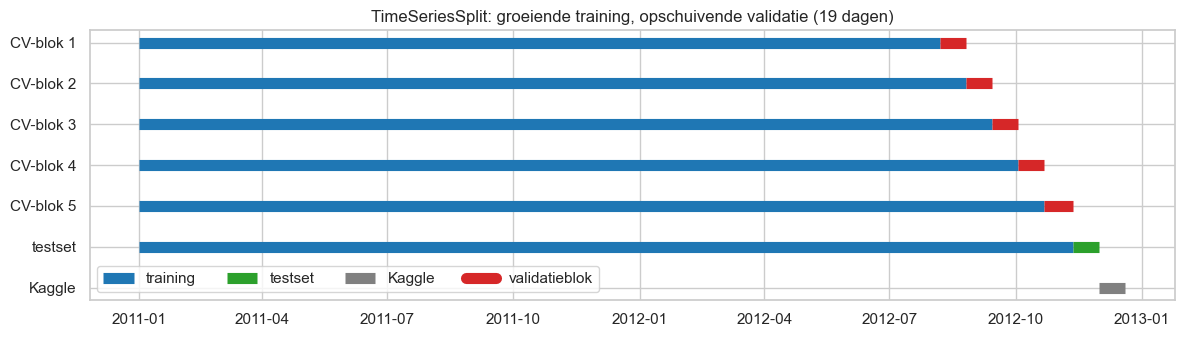

In [27]:
def plot_cv_folds(index, kaggle_index, n_splits=N_SPLITS, test_size=HORIZON):
    """
    Teken de trainings- en validatieblokken van TimeSeriesSplit, de testset
    en de Kaggle-periode (naar het voorbeeld in week 11, dia 5).

    Parameters
    ----------
    index : DatetimeIndex
        Tijdstippen van de gelabelde data.
    kaggle_index : DatetimeIndex
        Tijdstippen van de Kaggle-periode.
    n_splits : int, optional
        Aantal validatieblokken (default N_SPLITS).
    test_size : int, optional
        Lengte van elk blok en van de testset (default HORIZON).
    """
    train_part = index[:-test_size]
    kf = TimeSeriesSplit(n_splits=n_splits, test_size=test_size)
    fig, ax = plt.subplots(figsize=(14, 3.5))
    for i, (train_idx, val_idx) in enumerate(kf.split(train_part)):
        ax.hlines(i, train_part[train_idx[0]], train_part[train_idx[-1]],
                  color='tab:blue', lw=8)
        ax.hlines(i, train_part[val_idx[0]], train_part[val_idx[-1]],
                  color='tab:red', lw=8)
    ax.hlines(n_splits, index[0], index[-test_size - 1], color='tab:blue',
              lw=8, label='training')
    ax.hlines(n_splits, index[-test_size], index[-1], color='tab:green',
              lw=8, label='testset')
    ax.hlines(n_splits + 1, kaggle_index[0], kaggle_index[-1],
              color='grey', lw=8, label='Kaggle')
    ax.plot([], [], color='tab:red', lw=8, label='validatieblok')
    labels = [f'CV-blok {i + 1}' for i in range(n_splits)]
    ax.set_yticks(range(n_splits + 2), labels + ['testset', 'Kaggle'])
    ax.invert_yaxis()
    ax.legend(loc='lower left', ncol=4)
    ax.set_title('TimeSeriesSplit: groeiende training, opschuivende '
                 'validatie (19 dagen)')
    plt.show()


plot_cv_folds(df_model.index, df_kaggle.index)